In [191]:
import xarray as xr
from gliderflightOG1 import plotters, tools, utilities
from gliderflightOG1 import new_flightmodel as nfm
import numpy as np

import matplotlib.pyplot as plt
import importlib

from dissipationIFR import interactive, plots
from ipywidgets import interact, IntSlider

from pathlib import Path
project_root = Path.cwd().resolve().parent
plotting_style = str(project_root / "gliderflightOG1" / "flightmodels.mplstyle")

In [192]:
def calc_w_meas(glider):
    msk_hyd = ~np.isnan(glider["DEPTH"])
    w_meas = tools.time_derivative(glider['TIME'].values[msk_hyd], glider['DEPTH'].values[msk_hyd], n=2)
    w_meas_full = utilities.restore_masked_array(w_meas, msk_hyd)
    return w_meas_full

def change_dataset(ds):
    # 2. Rename and clean up fields as needed
    if "VBD" not in ds.data_vars:
        if "VBD_CC" in ds.data_vars:
            vbd_str = "VBD_CC"
        if "RELVBD" in ds.data_vars:
            vbd_str = "RELVBD"
        ds = ds.rename({
            vbd_str: 'VBD',
        })
    if "DIVENUM" not in ds.data_vars:
        if "DIVE_NUMBER" in ds.data_vars:
            dive_str = "DIVE_NUMBER"
        if "divenum" in ds.data_vars:
            dive_str = "divenum"
        ds = ds.rename({
            dive_str: 'DIVENUM',
        })
    if "LATITUDE" not in ds.coords:
        ds = ds.rename({
            "LAT": 'LATITUDE',"LON": 'LONGITUDE',
        })
    if "C_VBD" not in ds.data_vars:
        c_vbd = np.full_like(ds.VBD.values, 1000)
        ds['C_VBD'] = (('N_MEASUREMENTS',), c_vbd)

    # 3. Add missing variables and interpolate over NaNs if needed
        # a) Calculate vertical speed from dz/dt if needed and assign to original dataset
    w_meas_full = calc_w_meas(ds)
    ds['W_MEAS'] = (('N_MEASUREMENTS',), -w_meas_full * 100)  # Convert m/s to cm/s
    ds['W_MEAS'].assign_attrs(units='cm/s')  # Update units attribute


        # b) Interpolate over NaNs in VBD and PITCH
    ds = utilities.interpolate_over_nans(ds, 'VBD')
    ds = utilities.interpolate_over_nans(ds, 'PITCH')
    ds = utilities.interpolate_over_nans(ds, 'ROLL')


        # c) Create UPDN from PROFILE_NUMBER
    ds = ds.assign_coords(TIME=ds['TIME'])  # Make sure TIME is coordinate
    ds['UPDN'] = xr.where(ds['PROFILE_NUMBER']%2 == 1, -1, 1)

        # d) For later use, add heights from bathymetry and appogee
    ds = utilities.add_heights(ds)
    return ds

In [193]:
dataset_path = '/Users/u302042/Desktop/Master_thesis/Data/Glider/005/20080606/all_data_OG1.nc'

glider = xr.open_dataset(dataset_path)
glider = change_dataset(glider)

In [194]:
utilities.print_profile_diffs(glider, vars_to_print=["PITCH", "VBD", "TEMP","PRES","PSAL","GLIDE_SPEED","DEPTH"], n=10, position="beginning",profiles = None)


Profile 1.0:
t datetime[ns]                |     Δt [s] |      PITCH |        VBD |       TEMP |       PRES |       PSAL | GLIDE_SPEED |      DEPTH
--------------------------------------------------------------------------------------------------------------------------------------
2008-06-06T18:05:52.000000000 |   176.0000 |        nan |        nan |        nan |        nan |        nan |        nan |     0.0000
2008-06-06T18:08:18.000000000 |   146.0000 |   -67.3000 |   484.9600 |    11.3050 |     0.9260 |        nan |        nan |     0.3870
2008-06-06T18:08:38.000000000 |    20.0000 |   -63.4000 |   360.3500 |    11.3184 |     0.9361 |        nan |        nan |     0.3988
2008-06-06T18:08:58.000000000 |    20.0000 |   -69.0000 |   240.3900 |    11.3175 |     0.9763 |        nan |        nan |     0.4367
2008-06-06T18:09:18.000000000 |    20.0000 |   -66.1000 |   125.5900 |    11.2768 |     1.0871 |        nan |        nan |     0.5468
2008-06-06T18:09:38.000000000 |    20.0000 |  

In [195]:
params = nfm.FlightParameters()
params.hd_a = glider.HD_A.mean().values
params.hd_b = glider.HD_B.mean().values
params.hd_c = glider.HD_C.mean().values
params.vbd_min_cnts = glider.VBD_MIN_CNTS.values
params.vbd_cnts_per_cc = 1/glider.VBD_CC_PER_CNTS.values
params.volmax = glider.VOLMAX.values
params.mass = glider.MASS.values

params.temp_ref = 10.0
params.rho0 = 1027.5

fm = nfm.SteadyFlightModel(params=params)
fm.params

FlightParameters(hd_a=array(0.003836), hd_b=array(0.010078), hd_c=array(9.8541e-06), xl=1.8, mass=array(52.277), volmax=array(51459.), rho0=1027.5, vbd_bias=0.0, vbd_min_cnts=array(390), vbd_cnts_per_cc=np.float64(-4.076641014131309), temp_ref=10.0, therm_exp=7.05e-05, abs_compress=4.1e-06, tol=0.001, max_iter=15)

In [196]:
required = ('PRES', 'PSAL', 'TEMP', 'PITCH', 'VBD', 'C_VBD',
            'LATITUDE', 'LONGITUDE', 'W_MEAS', 'DEPTH')
valid_mask = np.logical_and.reduce([np.isfinite(glider[name].values) for name in required])
if not valid_mask.any():
    raise ValueError('No complete measurements are available for the flight model.')
fit_data = glider.isel(N_MEASUREMENTS=np.flatnonzero(valid_mask)).copy()

In [197]:
fm.solve_model(fit_data, which_par=np.array([1, 1, 1, 1, 1, 0]))

INFO:gliderflightOG1.new_flightmodel:🚁 Starting Glider Flight Model Parameter Optimization
INFO:gliderflightOG1.new_flightmodel:============================================================
INFO:gliderflightOG1.new_flightmodel:🔍 Initial Parameter Values:
INFO:gliderflightOG1.new_flightmodel:  hd_a: 0.003836
INFO:gliderflightOG1.new_flightmodel:  hd_b: 0.010078
INFO:gliderflightOG1.new_flightmodel:  vbd_bias: 0.0
INFO:gliderflightOG1.new_flightmodel:  abs_compress: 4.1e-06
INFO:gliderflightOG1.new_flightmodel:  therm_exp: 7.05e-05
INFO:gliderflightOG1.new_flightmodel:  hd_c: 9.8541e-06
INFO:gliderflightOG1.new_flightmodel:
The following parameters will be optimized:
INFO:gliderflightOG1.new_flightmodel:  hd_a
INFO:gliderflightOG1.new_flightmodel:  hd_b
INFO:gliderflightOG1.new_flightmodel:  vbd_bias
INFO:gliderflightOG1.new_flightmodel:  abs_compress
INFO:gliderflightOG1.new_flightmodel:  therm_exp
INFO:gliderflightOG1.new_flightmodel:🔄 Iteration 001 | Cost: 2.911831 | Params -> [hd_a: 3

Optimization terminated successfully.
         Current function value: 0.784081
         Iterations: 22
         Function evaluations: 38


<xarray.Dataset> Size: 48MB
Dimensions:                  (N_MEASUREMENTS: 322436)
Coordinates:
    DEPTH                    (N_MEASUREMENTS) float64 3MB 3.348 14.0 ... 0.5729
    LONGITUDE                (N_MEASUREMENTS) float64 3MB -8.274 ... -6.05
    LATITUDE                 (N_MEASUREMENTS) float64 3MB 61.41 61.42 ... 63.69
    TIME                     (N_MEASUREMENTS) datetime64[ns] 3MB 2008-06-06T1...
Dimensions without coordinates: N_MEASUREMENTS
Data variables: (12/41)
    GLIDER_VERT_VELO_MODEL   (N_MEASUREMENTS) float32 1MB ...
    THETA                    (N_MEASUREMENTS) float32 1MB ...
    TEMP                     (N_MEASUREMENTS) float32 1MB 11.09 10.78 ... 11.34
    GLIDE_SPEED              (N_MEASUREMENTS) float32 1MB 53.86 39.1 ... 28.12
    SIGTHETA                 (N_MEASUREMENTS) float32 1MB ...
    SIGMA_T                  (N_MEASUREMENTS) float32 1MB ...
    ...                       ...
    DEPLOYMENT_LATITUDE      float64 8B ...
    DEPLOYMENT_LONGITUDE     float64 8B ...
    DEPLOYMENT_TIME          datetime64[ns] 8B ...
    W_MEAS                   (N_MEASUREMENTS) float64 3MB -22.8 ... 0.1548
    UPDN                     (N_MEASUREMENTS) int64 3MB -1 -1 -1 -1 ... 1 1 1 1
    HEIGHT_ABOVE_APOGEE      (N_MEASUREMENTS) float64 3MB 48.01 37.36 ... 301.9
Attributes: (12/42)
    title:                                      OceanGliders trajectory file
    id:                                         sg005_20080606T180738_delayed
    platform:                                   sub-surface gliders
    platform_vocabulary:                        https://vocab.nerc.ac.uk/coll...
    naming_authority:                           edu.washington.apl
    institution:                                School of Oceanography\nUnive...
    ...                                         ...
    keywords_vocabulary:                        NASA/GCMD Earth Science Keywo...
    acknowledgment:                             National Science Foundation, ...
    file_version:                               2.71
    contributer_email:                          null@null.com
    Glider:                                     005
    Mission:                                    20080606

In [198]:
# Calculate vertical speed from the flight model
umag, theta = fm.compute_flight_speed(fit_data)
fit_data['UMAG'] = (('N_MEASUREMENTS',), umag)
fit_data['THETA'] = (('N_MEASUREMENTS',), theta)
fit_data['W_MODEL'] = (('N_MEASUREMENTS',), umag * np.sin(np.radians(theta)))
fit_data['W_WATER'] = fit_data['W_MEAS'] - fit_data['W_MODEL']


umag_full = utilities.restore_masked_array(umag, valid_mask)
theta_full = utilities.restore_masked_array(theta, valid_mask)
vert_speed_full = umag_full * np.sin(np.radians(theta_full))
# Assign the vertical speed to the original dataset, restoring the masked array to match the original size
glider['W_MODEL'] = (('N_MEASUREMENTS',), vert_speed_full)
# Calculate the vertical water velocity from the flight model and measured vertical speed
glider['W_WATER'] = glider['W_MEAS'] - glider['W_MODEL']
glider['W_WATER_BS3'] = glider['W_MEAS'] - glider['GLIDER_VERT_VELO_MODEL']

In [199]:
interactive.interactive_profile(glider)

Output()

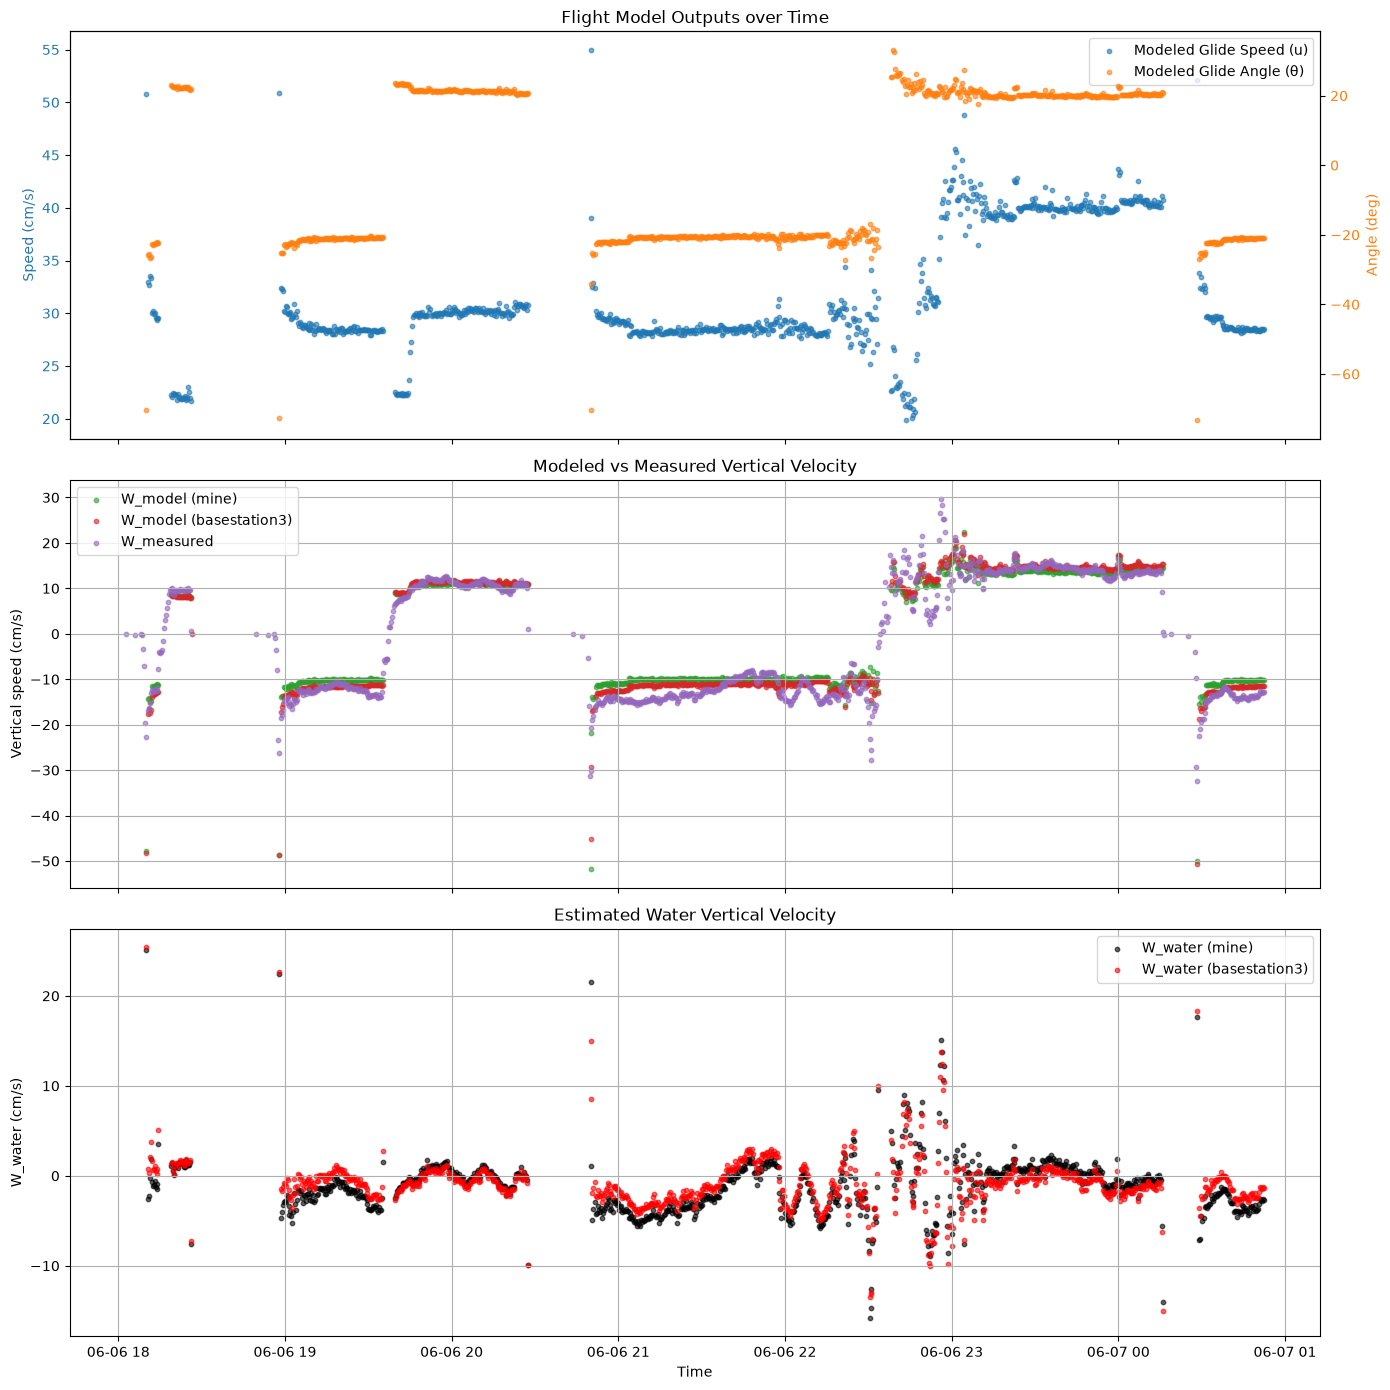

In [200]:
dzdt = glider.W_MEAS.values
idx = 0
n = 1000
sel = slice(idx, idx + n)

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)
s = 10

# 1) Glide speed and angle (different colors / twin y)
ax1 = axes[0]
p1 = ax1.scatter(glider['TIME'][sel], umag_full[sel], c='tab:blue', s=s, alpha=0.6, label='Modeled Glide Speed (u)')
ax1.set_ylabel('Speed (cm/s)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_title('Flight Model Outputs over Time')

ax1_twin = ax1.twinx()
p2 = ax1_twin.scatter(glider['TIME'][sel], theta_full[sel], c='tab:orange', s=s, alpha=0.6, label='Modeled Glide Angle (θ)')
ax1_twin.set_ylabel('Angle (deg)', color='tab:orange')
ax1_twin.tick_params(axis='y', labelcolor='tab:orange')

# combined legend
handles = [p1, p2]
labels = [h.get_label() for h in handles]
ax1.legend(handles, labels, loc='upper right')

# 2) Modeled vertical velocity comparison (mine vs basestation3) + measured
ax2 = axes[1]
ax2.scatter(glider['TIME'][sel], vert_speed_full[sel], s=s, alpha=0.6, label='W_model (mine)', color='tab:green')
bs3_vert = glider['GLIDER_VERT_VELO_MODEL'].values
ax2.scatter(glider['TIME'][sel], bs3_vert[sel], s=s, alpha=0.6, label='W_model (basestation3)', color='tab:red')
ax2.scatter(glider['TIME'][sel], dzdt[sel], s=s, alpha=0.6, label='W_measured', color='tab:purple')
ax2.set_ylabel('Vertical speed (cm/s)')
ax2.set_title('Modeled vs Measured Vertical Velocity')
ax2.legend()
ax2.grid(True)

# 3) W_water comparison (basestation3 vs mine)
ax3 = axes[2]
ax3.scatter(glider['TIME'][sel], glider['W_WATER'].values[sel], s=s, alpha=0.6, label='W_water (mine)', color='black')
ax3.scatter(glider['TIME'][sel], glider['W_WATER_BS3'].values[sel], s=s, alpha=0.6, label='W_water (basestation3)', color='red')
ax3.set_ylabel('W_water (cm/s)')
ax3.set_title('Estimated Water Vertical Velocity')
ax3.set_xlabel('Time')
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

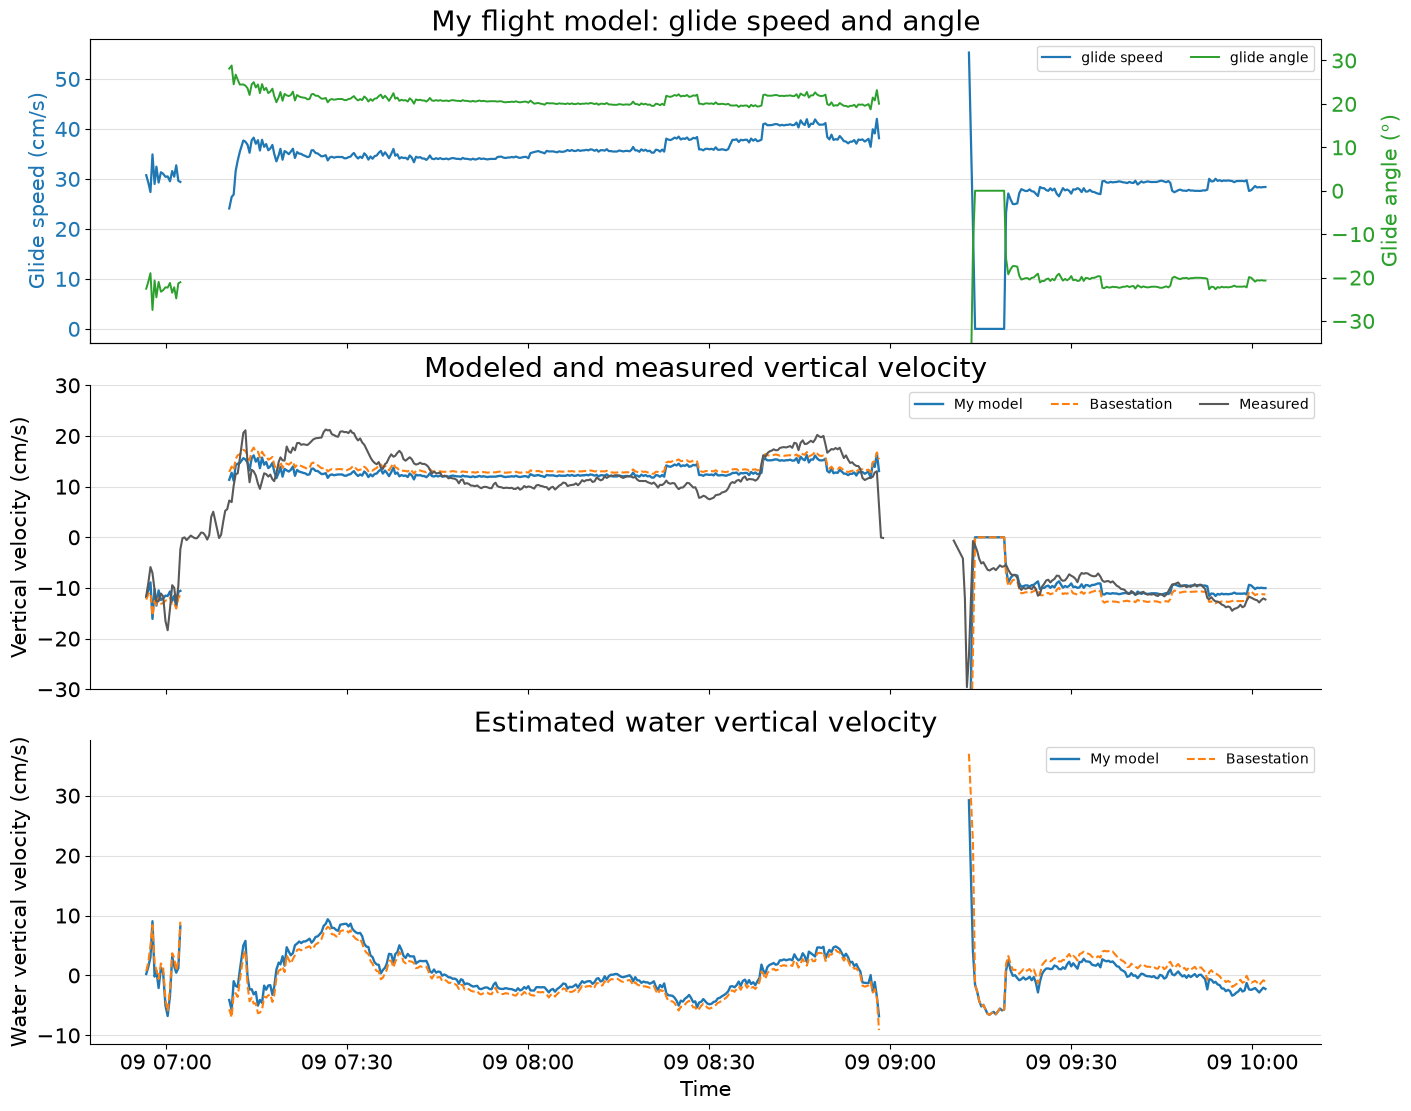

In [201]:
import matplotlib.pyplot as plt

idx, n = 9970, 500
sel = slice(idx, idx + n)
time = glider["TIME"].values[sel]

mine = "tab:blue"
basestation = "tab:orange"
measured = "0.35"

with plt.style.context(plotting_style):

    fig, axes = plt.subplots(
        3, 1, figsize=(14, 11), sharex=True, constrained_layout=True
    )

    # Glide speed and angle
    ax = axes[0]
    speed_line, = ax.plot(
        time, umag_full[sel], color=mine, lw=1.6, label="glide speed"
    )
    ax.set_ylabel("Glide speed (cm/s)", color=mine)
    ax.tick_params(axis="y", labelcolor=mine)

    angle_ax = ax.twinx()
    angle_line, = angle_ax.plot(
        time, theta_full[sel], color="tab:green", lw=1.4,
        label="glide angle"
    )
    angle_ax.set_ylabel("Glide angle (°)", color="tab:green")
    angle_ax.tick_params(axis="y", labelcolor="tab:green")
    ax.legend(handles=[speed_line, angle_line], ncol=2, fontsize=10)
    ax.set_title("My flight model: glide speed and angle")
    angle_ax.set_ylim(-35, 35)

    # Vertical velocity
    ax = axes[1]
    ax.plot(
        time, vert_speed_full[sel], color=mine, lw=1.7,
        label="My model"
    )
    ax.plot(
        time, glider["GLIDER_VERT_VELO_MODEL"].values[sel],
        color=basestation, lw=1.5, ls="--", label="Basestation"
    )
    ax.plot(
        time, glider["W_MEAS"].values[sel], color=measured,
        lw=1.5, label="Measured"
    )
    #ax.scatter(
    #    time, glider["W_MEAS"].values[sel], color=measured,
    #    s=8, alpha=0.45, label="Measured", zorder=3
    #)
    ax.set_ylabel("Vertical velocity (cm/s)")
    ax.set_title("Modeled and measured vertical velocity")
    ax.legend(ncol=3, fontsize=10)
    ax.set_ylim(-30, 30)

    # Water vertical velocity
    ax = axes[2]
    ax.plot(
        time, glider["W_WATER"].values[sel], color=mine,
        lw=1.7, label="My model"
    )
    ax.plot(
        time, glider["W_WATER_BS3"].values[sel], color=basestation,
        lw=1.5, ls="--", label="Basestation"
    )
    ax.set_ylabel("Water vertical velocity (cm/s)")
    ax.set_title("Estimated water vertical velocity")
    ax.set_xlabel("Time")
    ax.legend(ncol=2, fontsize=10)

    for ax in axes:
        ax.grid(axis="y", color="0.88", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)

    plt.show()

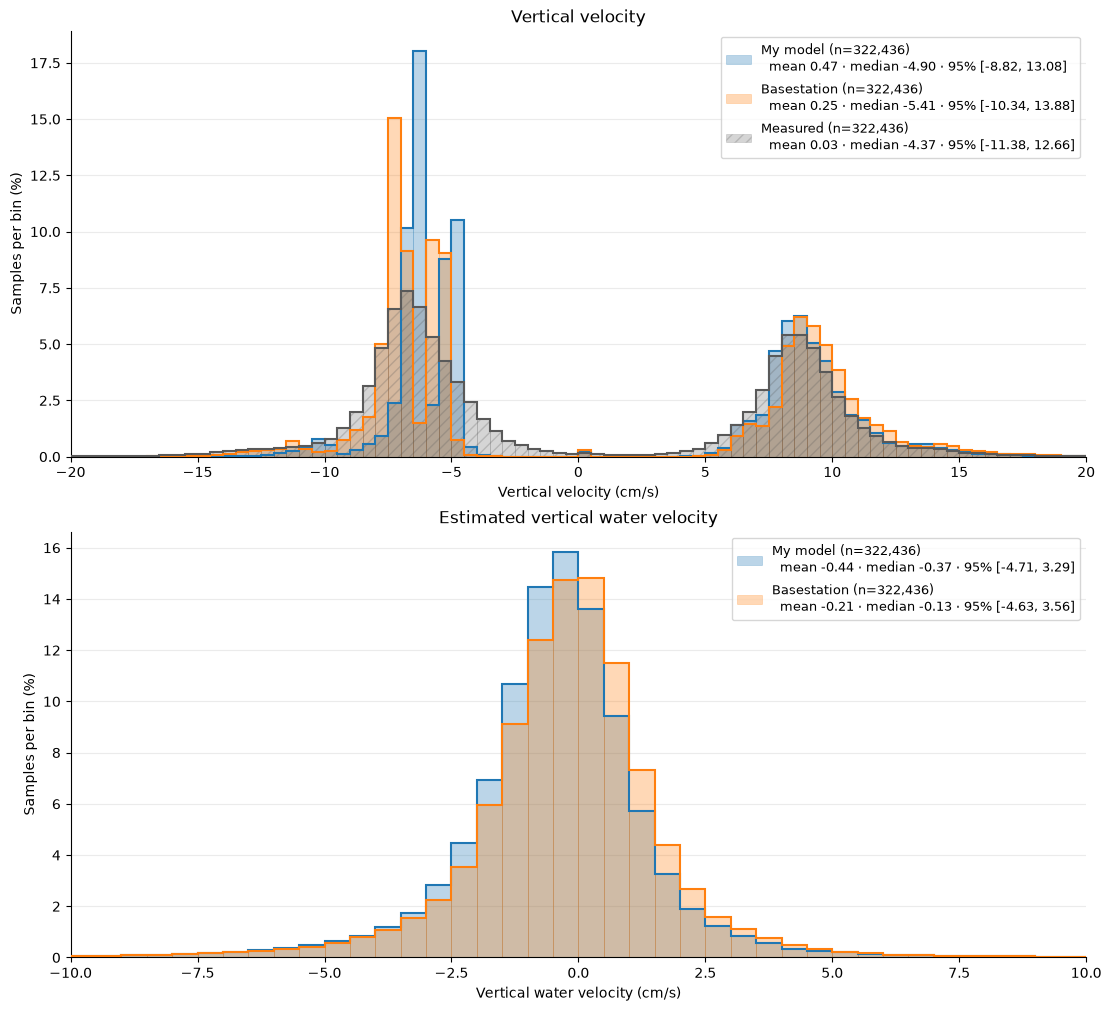

In [202]:
import numpy as np
import matplotlib.pyplot as plt

styles = {
    "My model":   {"color": "tab:blue",   "alpha": 0.30, "hatch": ""},
    "Basestation": {"color": "tab:orange", "alpha": 0.30, "hatch": ""},
    "Measured":   {"color": "0.35",       "alpha": 0.25, "hatch": "///"},
}

def plot_distributions(ax, series, title, xlabel, bin_width=0.5):
    values = {name: np.asarray(data, dtype=float) for name, data in series.items()}

    valid = np.logical_and.reduce([np.isfinite(v) for v in values.values()])
    if not valid.any():
        raise ValueError(f"No jointly valid samples for {title}")
    values = {name: v[valid] for name, v in values.items()}

    combined = np.concatenate(list(values.values()))
    bins = np.arange(
        np.floor(combined.min() / bin_width) * bin_width,
        np.ceil(combined.max() / bin_width) * bin_width + bin_width,
        bin_width,
    )

    for name, v in values.items():
        style = styles[name]
        mean, median = np.mean(v), np.median(v)
        low, high = np.percentile(v, [2.5, 97.5])

        ax.hist(
            v,
            bins=bins,
            weights=np.full(len(v), 100 / len(v)),
            histtype="bar",
            color=style["color"],
            edgecolor=style["color"],
            linewidth=0.5,
            alpha=style["alpha"],
            hatch=style["hatch"],
            label=(f"{name} (n={len(v):,})\n"
                   f"  mean {mean:.2f} · median {median:.2f}"
                   f" · 95% [{low:.2f}, {high:.2f}]"),
        )
        # Crisp outline over the same bins
        ax.hist(v, bins=bins, weights=np.full(len(v), 100 / len(v)),
        histtype="step", color=style["color"],
        linewidth=1.5, zorder=5)
        #ax.axvline(
        #    mean, color=style["color"], linestyle="--",
        #    linewidth=1.5, alpha=0.9,
        #)

    ax.set(title=title, xlabel=xlabel, ylabel="Samples per bin (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(2, 1, figsize=(11, 10), constrained_layout=True)

plot_distributions(
    axes[0],
    {
        "My model": vert_speed_full,
        "Basestation": glider["GLIDER_VERT_VELO_MODEL"].values,
        "Measured": glider["W_MEAS"].values,
    },
    "Vertical velocity",
    "Vertical velocity (cm/s)",
)
axes[0].set_xlim(-20, 20)

plot_distributions(
    axes[1],
    {
        "My model": glider["W_WATER"].values,
        "Basestation": glider["W_WATER_BS3"].values,
    },
    "Estimated vertical water velocity",
    "Vertical water velocity (cm/s)",
)
axes[1].set_xlim(-10, 10)

plt.show()

In [203]:
### plot vertical profile for whole dataset for down and upcast
from gliderflightOG1 import utilities

ds = glider
binning = 1 #m
var = "W_WATER_BS3"
unit = "cm/s"
grid = utilities.regular_grid(ds.DEPTH.values, res = binning)
up_msk = ds["UPDN"].values == 1
down_msk = ds["UPDN"].values == -1

def return_grids(depth, profile, values, grid, agg):
    return utilities.construct_2dgrid(depth, profile, values, xi=grid, yi=ds.PROFILE_NUMBER.max()+1, agg=agg)[0].flatten()

low, high = 2.5, 97.5
p_low = lambda x: np.nanpercentile(x, low)
p_high = lambda x: np.nanpercentile(x, high)


args = lambda msk: (ds.DEPTH.values[msk], ds.PROFILE_NUMBER.values[msk], ds[var].values[msk], grid)

climb_mean, XI, _ = utilities.construct_2dgrid(ds.DEPTH.values[down_msk], ds.PROFILE_NUMBER.values[down_msk], ds[var].values[down_msk],xi =  grid, yi = ds.PROFILE_NUMBER.max()+1 , agg='mean')

climb_median, climb_std, climb_p_low, climb_p_high = [return_grids(*args(down_msk), a) for a in ["median", "std", p_low, p_high]]
dive_mean, dive_median, dive_std, dive_p_low, dive_p_high = [return_grids(*args(up_msk), a) for a in ["mean", "median", "std", p_low, p_high]]

climb_mean, XI = climb_mean.flatten(), XI.flatten()

grid_hab = np.arange(-binning/2, np.nanmax(ds.HEIGHT_ABOVE_APOGEE.values) + binning/2, binning)

args_hab = lambda msk: (ds.HEIGHT_ABOVE_APOGEE.values[msk], ds.PROFILE_NUMBER.values[msk], ds[var].values[msk], grid_hab)

climb_hab_mean, HAB, _ = utilities.construct_2dgrid(*args_hab(down_msk), yi=ds.PROFILE_NUMBER.max() + 1, agg="mean")
climb_hab_mean, HAB = climb_hab_mean.flatten(), HAB.flatten()

climb_hab_median, climb_hab_std, climb_hab_p_low, climb_hab_p_high = [return_grids(*args_hab(down_msk), a) for a in ["median", "std", p_low, p_high]]
dive_hab_mean, dive_hab_median, dive_hab_std, dive_hab_p_low, dive_hab_p_high = [return_grids(*args_hab(up_msk), a) for a in ["mean", "median", "std", p_low, p_high]]

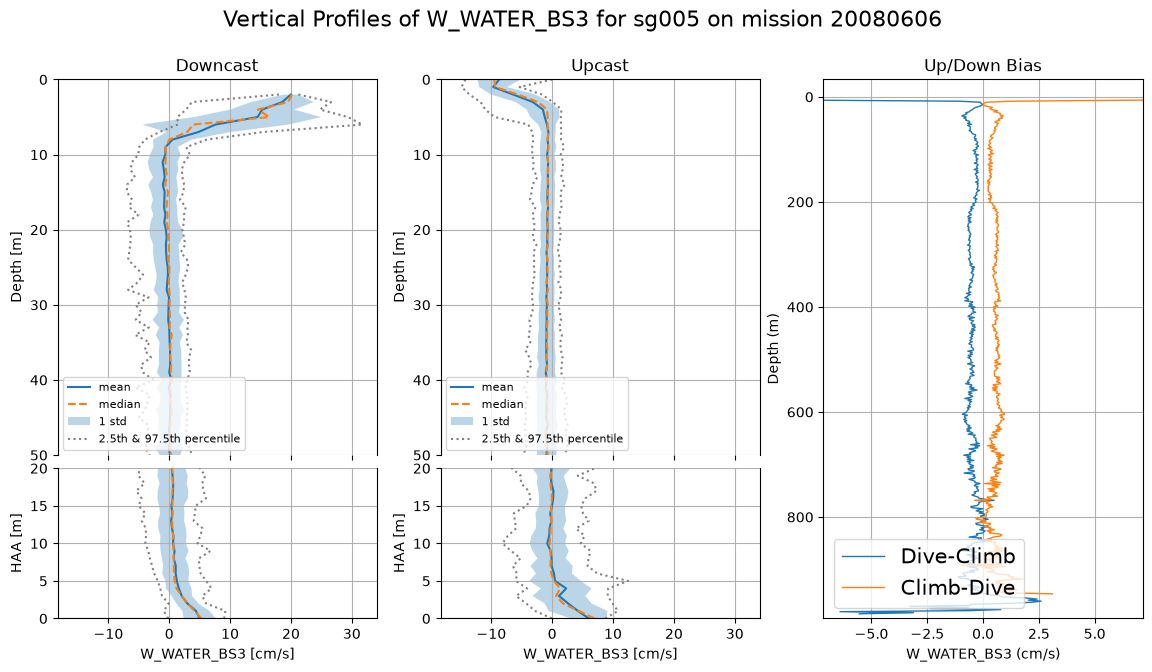

In [204]:
from glidertest import plots

max_depth = 50
max_hab = 20

fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(
    2, 3,
    height_ratios=[max_depth, max_hab],   # <-- proportional heights
    hspace=0.05,
    width_ratios=[1, 1, 1],
)

### Downcast plotting ###
ax0 = fig.add_subplot(gs[0, 0])                 # depth
ax0_hab = fig.add_subplot(gs[1, 0], sharex=ax0) # HAB
# Depth
ax0.plot(climb_mean, XI, label="mean")
ax0.plot(climb_median, XI, "--", label="median")
ax0.fill_betweenx(XI, climb_mean-climb_std, climb_mean+climb_std, alpha=0.3, label="1 std")
ax0.plot(climb_p_low, XI, ":", label=f"{low}th & {high}th percentile", color="gray")
ax0.plot(climb_p_high, XI, ":", color = "gray")

# HAB
ax0_hab.plot(climb_hab_mean, HAB, label="mean")
ax0_hab.plot(climb_hab_median, HAB, "--", label="median")
ax0_hab.fill_betweenx(HAB, climb_hab_mean-climb_hab_std, climb_hab_mean+climb_hab_std, alpha=0.3, label="1 std")
ax0_hab.plot(climb_hab_p_low, HAB, ":", label=f"{low}th & {high}th percentile", color="gray")
ax0_hab.plot(climb_hab_p_high, HAB, ":", color = "gray")


###  Upcast plotting ###
ax1 = fig.add_subplot(gs[0, 1], sharex=ax0)
ax1_hab = fig.add_subplot(gs[1, 1], sharex=ax1)
# Depth
ax1.plot(dive_mean, XI, label="mean")
ax1.plot(dive_median, XI, "--", label="median")
ax1.fill_betweenx(XI, dive_mean-dive_std, dive_mean+dive_std, alpha=0.3, label="1 std")
ax1.plot(dive_p_low, XI, ":", label=f"{low}th & {high}th percentile", color="gray")
ax1.plot(dive_p_high, XI, ":", color = "gray")

# HAB
ax1_hab.plot(dive_hab_mean, HAB, label="mean")
ax1_hab.plot(dive_hab_median, HAB, "--", label="median")
ax1_hab.fill_betweenx(HAB, dive_hab_mean-dive_hab_std, dive_hab_mean+dive_hab_std, alpha=0.3, label="1 std")
ax1_hab.plot(dive_hab_p_low, HAB, ":", label=f"{low}th & {high}th percentile", color="gray")
ax1_hab.plot(dive_hab_p_high, HAB, ":", color = "gray")



## set the same xlim for both depth and hab plots
for a, a_hab in zip((ax0, ax1), (ax0_hab, ax1_hab)):
    a.set_ylim(max_depth, 0)
    a_hab.set_ylim(0, max_hab)
    # Hide touching spines
    a.spines["bottom"].set_visible(False)
    a_hab.spines["top"].set_visible(False)
    a.tick_params(labelbottom=False)
    a.set_ylabel("Depth [m]")
    a_hab.set_ylabel("HAA [m]")
    a.grid()
    a_hab.grid()
    a_hab.set_xlabel(f"{var} [{unit}]")
    a.legend(loc = "lower left", fontsize=8)
    #a.set_xlim([-0.01, 0.01])
    #a.set_xlim([-40, 22])
    

ax0.set_title("Downcast")
ax1.set_title("Upcast")


# Bias plot spans both rows
ax2 = fig.add_subplot(gs[:, 2])
ax2.set_title("Up/Down Bias")
plots.plot_updown_bias(ds=ds, var=var, v_res=2, ax=ax2)

### add figure title
fig.suptitle(f"Vertical Profiles of {var} for sg{ds.id.split('_')[0][2:5]} on mission {ds.id.split('_')[1][0:8]}", fontsize=16)

save_path = "/Users/u302042/Desktop/Research_diary/Figures/Flightmodel/"
#fig.savefig(f"{save_path}Profile_{var}_sg{ds.id.split('_')[0][2:5]}_{ds.id.split('_')[1][0:8]}.png", dpi=300, bbox_inches='tight')

The model assumes the velocity is much faster downwards at the surface (dive) than it actually is

/Users/u302042/miniconda3/envs/gliderflightOG1/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:1328: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2) / (dx1 * (dx1 + dx2))
/Users/u302042/miniconda3/envs/gliderflightOG1/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:1329: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/Users/u302042/miniconda3/envs/gliderflightOG1/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:1330: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))


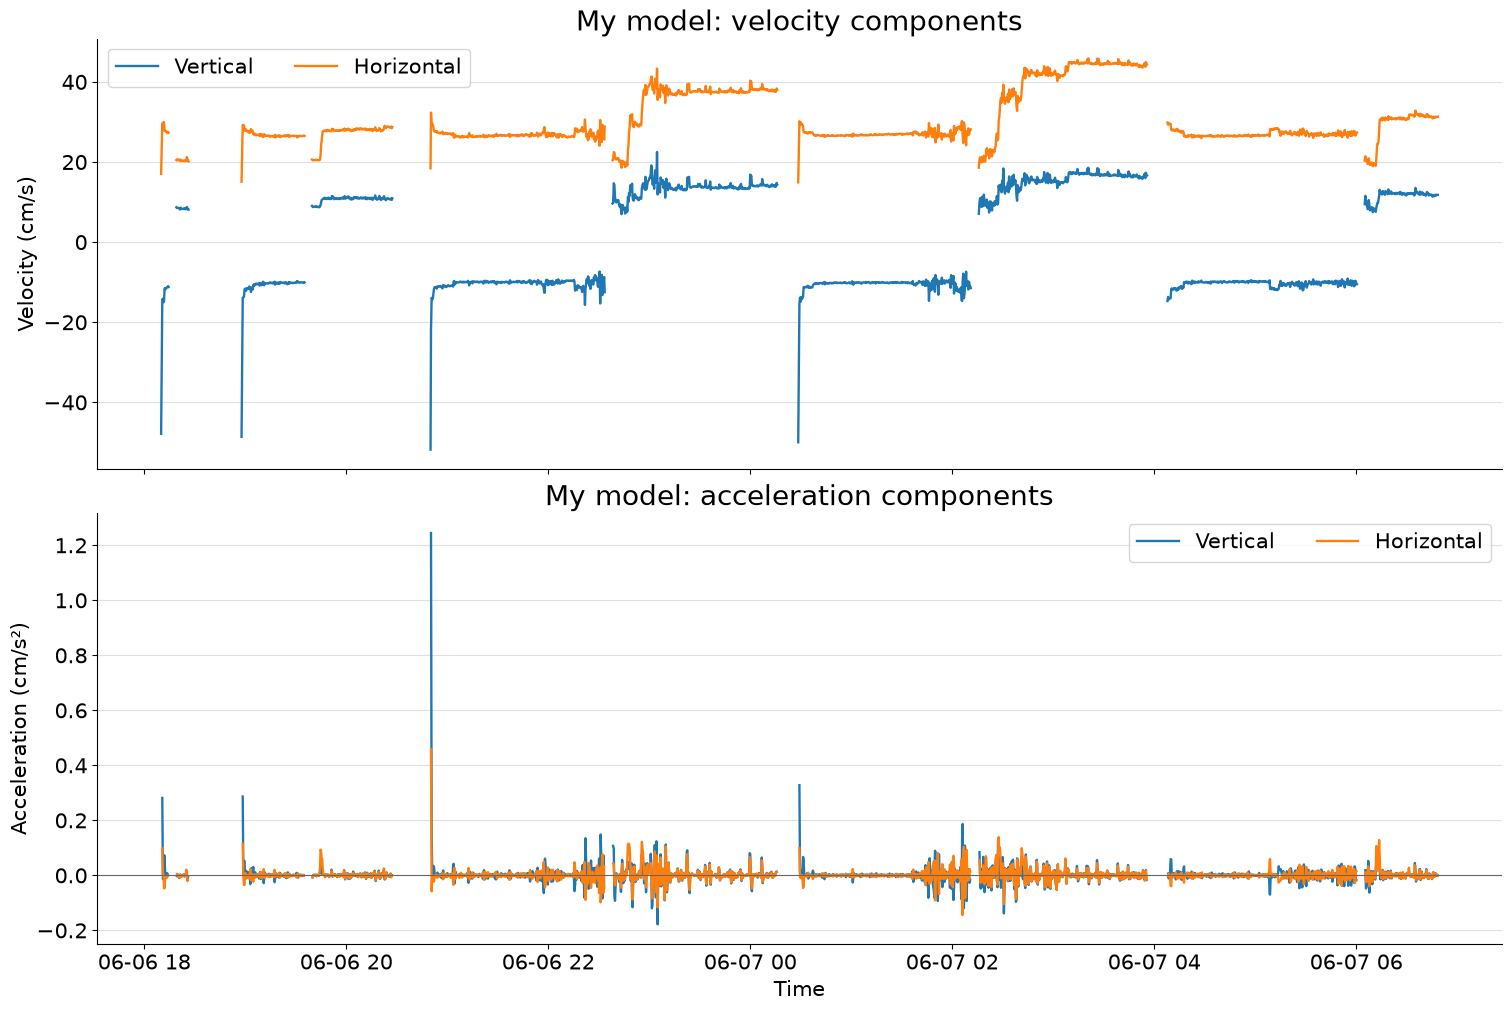

In [205]:
import numpy as np
import matplotlib.pyplot as plt

idx, n = 0, 2000
sel = slice(idx, idx + n)

time = glider["TIME"].values[sel]
angle = np.radians(theta_full[sel])
vertical = umag_full[sel] * np.sin(angle)
horizontal = umag_full[sel] * np.cos(angle)

# Convert timestamps to elapsed seconds for acceleration in cm/s².
elapsed_s = (time - time[0]) / np.timedelta64(1, "s")
vertical_accel = np.gradient(vertical, elapsed_s)
vertical_accel2 = tools.time_derivative(time, vertical, n=2)
horizontal_accel = np.gradient(horizontal, elapsed_s)
horizontal_accel2 = tools.time_derivative(time, horizontal, n=2)

with plt.style.context(plotting_style):
    fig, axes = plt.subplots(
        2, 1, figsize=(15, 10), sharex=True, constrained_layout=True
    )

    axes[0].plot(time, vertical, color="tab:blue", lw=1.7,
                 label="Vertical")
    axes[0].plot(time, horizontal, color="tab:orange", lw=1.7,
                 label="Horizontal")
    axes[0].set_ylabel("Velocity (cm/s)")
    axes[0].set_title("My model: velocity components")
    axes[0].legend(ncol=2)

    axes[1].plot(time, vertical_accel, color="tab:blue", lw=1.7,
                 label="Vertical")
    axes[1].plot(time, horizontal_accel, color="tab:orange", lw=1.7,
                  label="Horizontal")
    #axes[1].plot(time, vertical_accel2, color="tab:orange", lw=1.7,
    #                 label="Vertical")
    ## axes[1].plot(time, horizontal_accel2, color="tab:blue", lw=1.7,
    #                  label="Horizontal")
    axes[1].axhline(0, color="0.4", lw=0.8)
    axes[1].set_ylabel("Acceleration (cm/s²)")
    axes[1].set_xlabel("Time")
    axes[1].set_title("My model: acceleration components")
    axes[1].legend(ncol=2)

    for ax in axes:
        ax.grid(axis="y", color="0.88", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)

    plt.show()